# `Credit Scoring Model`

### **Problem**
A bank wants to know, before giving a loan, whether a person is likely to pay it back.
In this project I predict whether a borrower will be **90+ days late on a payment within the next 2 years** (`SeriousDlqin2yrs = 1`) using their past financial history.

**Which mistake is worse?**
- If the model says a risky person is safe (False Negative), the bank gives the loan and may lose the money.
- If the model says a safe person is risky (False Positive), the bank only loses a customer.

So catching defaulters (**recall**) matters more than overall accuracy.

**Dataset:** [Give Me Some Credit](https://www.kaggle.com/datasets/brycecf/give-me-some-credit-dataset?select=cs-training.csv), Kaggle (`cs-training.csv`), 150,000 borrowers.

**Models:** Logistic Regression, Decision Tree, Random Forest
**Metrics:** Precision, Recall, F1-Score, ROC-AUC

# `Libraries`

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = 'SeriousDlqin2yrs'

# `Data Loading & Understanding`

In [3]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
file_path = os.path.join(parent_dir, "data", "cs-training.csv")
df = pd.read_csv(file_path)
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

The dataset has 150,000 rows and 12 columns. All columns are numbers, so no mapping is needed.
- `Unnamed: 0` is only a row number, so I will drop it.<br>
- `MonthlyIncome` and `NumberOfDependents` have fewer non-null values than the other columns, so they have missing data.

In [5]:
df = df.drop(columns=['Unnamed: 0'])
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


**What I noticed in `describe()`:**
- `SeriousDlqin2yrs` mean is 0.068, so only **6.8% of people defaulted**. The data is imbalanced.
- `age` minimum is **0**, which is impossible for a borrower.
- The three late-payment columns have a max of **98**, but the 75th percentile is 0.
- `RevolvingUtilizationOfUnsecuredLines` should be between 0 and 1, but the max is **50,708**.
- `DebtRatio` median is 0.37 but the mean is 353, and `MonthlyIncome` goes up to 3 million while the median is 5,400. Both have some extremely large values.

# `Data Checking`
### Missing values

In [6]:
df.isnull().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

`MonthlyIncome` has 29,731 missing values (almost 20%) and `NumberOfDependents` has 3,924 (almost 2.6%). 
20% is too much to delete, so it will be filled later.

### Duplicates

In [7]:
duplicate = df[df.duplicated()]
duplicate.count()

SeriousDlqin2yrs                        609
RevolvingUtilizationOfUnsecuredLines    609
age                                     609
NumberOfTime30-59DaysPastDueNotWorse    609
DebtRatio                               609
MonthlyIncome                            99
NumberOfOpenCreditLinesAndLoans         609
NumberOfTimes90DaysLate                 609
NumberRealEstateLoansOrLines            609
NumberOfTime60-89DaysPastDueNotWorse    609
NumberOfDependents                      513
dtype: int64

### Age

In [8]:
df['age'].unique()

array([ 45,  40,  38,  30,  49,  74,  57,  39,  27,  51,  46,  76,  64,
        78,  53,  43,  25,  32,  58,  50,  69,  24,  28,  62,  42,  75,
        26,  52,  41,  81,  31,  68,  70,  73,  29,  55,  35,  72,  60,
        67,  36,  56,  37,  66,  83,  34,  44,  48,  61,  80,  47,  59,
        77,  63,  54,  33,  79,  65,  86,  92,  23,  87,  71,  22,  90,
        97,  84,  82,  91,  89,  85,  88,  21,  93,  96,  99,  94,  95,
       101,  98, 103, 102, 107, 105,   0, 109])

Most ages are between 21 and 109, but there is one **0**. A borrower cannot be 0 years old, so this is a **data entry error**.

### Late payment columns & Values

In [9]:
LATE_COLS = []
for col in df.columns:
    if df[col].max() == 98:
        LATE_COLS.append(col)
LATE_COLS

['NumberOfTime30-59DaysPastDueNotWorse',
 'NumberOfTimes90DaysLate',
 'NumberOfTime60-89DaysPastDueNotWorse']

In [10]:
for col in LATE_COLS:
    print(col, sorted(df[col].unique()))

NumberOfTime30-59DaysPastDueNotWorse [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(96), np.int64(98)]
NumberOfTimes90DaysLate [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(96), np.int64(98)]
NumberOfTime60-89DaysPastDueNotWorse [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(11), np.int64(96), np.int64(98)]


### Other suspicious values

In [11]:
checks = {
    "age < 18:": (df["age"] < 18).sum(),
    "late count is 96 or 98:": df[LATE_COLS].isin([96, 98]).any(axis=1).sum(),
    "utilization > 1:": (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum(),
    "utilization > 10:": (df["RevolvingUtilizationOfUnsecuredLines"] > 10).sum(),
    "DebtRatio > 1:": (df["DebtRatio"] > 1).sum(),
    "MonthlyIncome == 0:": (df["MonthlyIncome"] == 0).sum(),
}
pd.Series(checks, name="rows")

age < 18:                      1
late count is 96 or 98:      269
utilization > 1:            3321
utilization > 10:            241
DebtRatio > 1:             35137
MonthlyIncome == 0:         1634
Name: rows, dtype: int64

- Only **1** row has an impossible age.
- **269** rows have the 96/98 code.
- **3,321** people use more than their credit limit, but only **241** use more than 10 times their limit. Going a little over the limit can happen, but 10x is not realistic.
- **35,137** rows (23%) have DebtRatio above 1. That is too many to be random mistakes, so there must be a reason.

So two things need a closer look: 
- the **96/98** codes and 
- the very large DebtRatio values.

### Are the 96/98 rows just noise?

In [12]:
code_rows = df[LATE_COLS].isin([96, 98]).any(axis=1)

print("Default rate, rows with 96/98 codes:", round(df.loc[code_rows, TARGET].mean() * 100, 1), "%")
print("Default rate, all other rows       :", round(df.loc[~code_rows, TARGET].mean() * 100, 1), "%")

Default rate, rows with 96/98 codes: 54.6 %
Default rate, all other rows       : 6.6 %


**Important finding:** people with the 96/98 code default at **54.6%**, while everyone else defaults at **6.6%**, about **8 times more**.
If I simply replaced 98 with 0, the model would think these people were never late, and this strong `warning sign` would be lost.
**Decision:** So creating a new column `late_code_flag` then replacing the code **96/98** code with **0**.

### Why is DebtRatio so large?

In [13]:
df.groupby(df['MonthlyIncome'].isnull())['DebtRatio'].median()

MonthlyIncome
False       0.296023
True     1159.000000
Name: DebtRatio, dtype: float64

When income is present, the median DebtRatio is almost 0.3. When income is **missing**, it jumps to over 1,000.
DebtRatio is `debt / income`, so without income it cannot be a real ratio. I think in these rows it looks like the raw debt amount was stored instead.

**Decision:** Creating an `income_missing` column will help the model tell these rows apart.

# `Data Cleaning`

In [14]:
# Removing the duplicate rows
df.drop_duplicates(inplace=True)
df.shape

(149391, 11)

In [15]:
# Removing the rows with age 0
df = df[df['age'] > 0]
df.shape

(149390, 11)

In [16]:
# Creating a new column to flag rows with late codes 96 or 98
df['late_code_flag'] = df[LATE_COLS].isin([96, 98]).any(axis=1).astype(int)

# Replacing the late codes 96 and 98 with 0 in the late columns
for col in LATE_COLS:
    df[col] = df[col].replace([96, 98], 0)
df[LATE_COLS].max()

NumberOfTime30-59DaysPastDueNotWorse    13
NumberOfTimes90DaysLate                 17
NumberOfTime60-89DaysPastDueNotWorse    11
dtype: int64

In [17]:
# Finding the rows with missing MonthlyIncome values
df['income_missing'] = df['MonthlyIncome'].isnull()
df['income_missing'].unique()

array([False,  True])

In [18]:
# Mapping the boolean values in the 'income_missing' column to integers (1 for True, 0 for False)
income_missing_mapping = {
    True: 1,
    False: 0
}
df['income_missing'] = df['income_missing'].map(income_missing_mapping)
df['income_missing'].unique()

array([0, 1])

In [19]:
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

# `Feature Engineering`

In [20]:
df['total_late'] = df[LATE_COLS].sum(axis=1)

In [21]:
# Check if the person uses more than their credit limit
df['over_limit'] = df['RevolvingUtilizationOfUnsecuredLines'] > 1
df['over_limit'].unique()

array([False,  True])

In [22]:
# Mapping the boolean values in the 'over_limit' column to integers (1 for True, 0 for False)
over_limit_mapping = {
    True: 1,
    False: 0
}
df['over_limit'] = df['over_limit'].map(over_limit_mapping)
df['over_limit'].unique()

array([0, 1])

In [23]:
print(df['over_limit'].value_counts())
print(df['total_late'].value_counts())

over_limit
0    146069
1      3321
Name: count, dtype: int64
total_late
0     119308
1      17231
2       5942
3       2884
4       1595
5        940
6        592
7        380
8        197
9        125
10        73
11        53
13        19
12        18
14        13
15         9
17         4
16         4
19         2
18         1
Name: count, dtype: int64


- `over_limit`: **3,321** people (2.2%) use more than their credit limit. It is a small group.
- `total_late`: about **80%** of people were never late. The number of people drops quickly as late payments increase (17,231 people were late once, but only 73 were late 10 times). The maximum is now 19, which is realistic after removing the 96/98 codes.

# `Exploratory Data Analysis (EDA)`

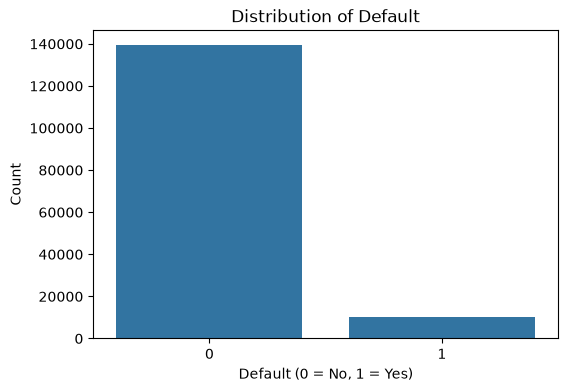

In [24]:
# Visualizing the distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title('Distribution of Default')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

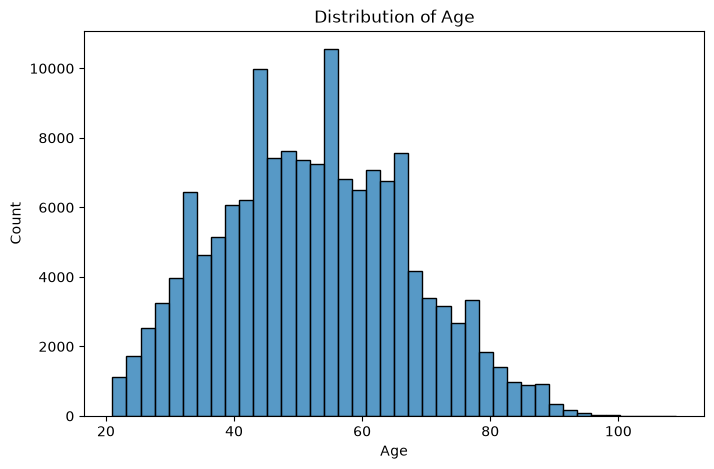

In [25]:
# Visualizing the distribution of age
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', bins=40)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

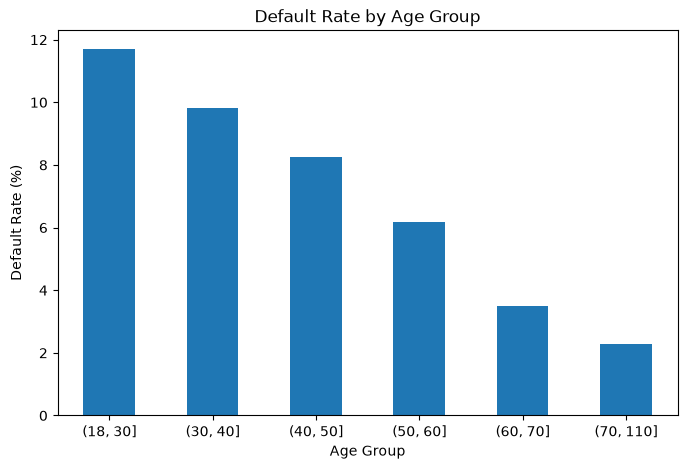

In [26]:
# Visualizing the default rate by age group
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 40, 50, 60, 70, 110])
age_rate = df.groupby('age_group', observed=True)[TARGET].mean() * 100

plt.figure(figsize=(8, 5))
age_rate.plot(kind='bar')
plt.title('Default Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()

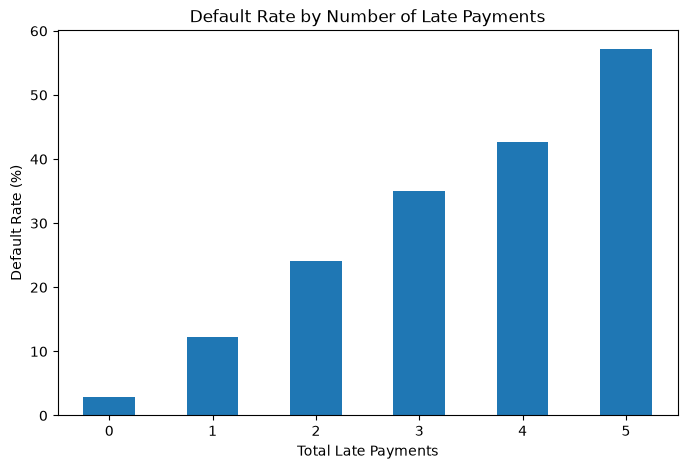

In [27]:
# Visualizing the default rate by number of late payments
df['late_group'] = df['total_late'].clip(upper=5)
late_rate = df.groupby('late_group')[TARGET].mean() * 100

plt.figure(figsize=(8, 5))
late_rate.plot(kind='bar')
plt.title('Default Rate by Number of Late Payments')
plt.xlabel('Total Late Payments')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()

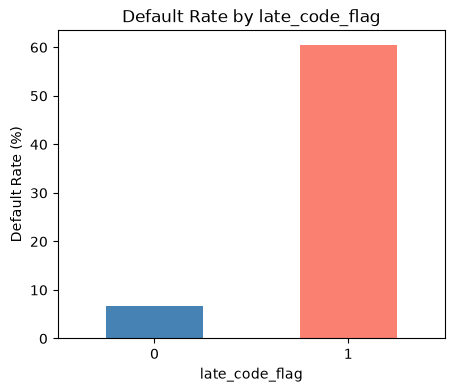

In [28]:
# Visualizing the default rate by late_code_flag
flag_rate = df.groupby('late_code_flag')[TARGET].mean() * 100

plt.figure(figsize=(5, 4))
flag_rate.plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Default Rate by late_code_flag')
plt.xlabel('late_code_flag')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()

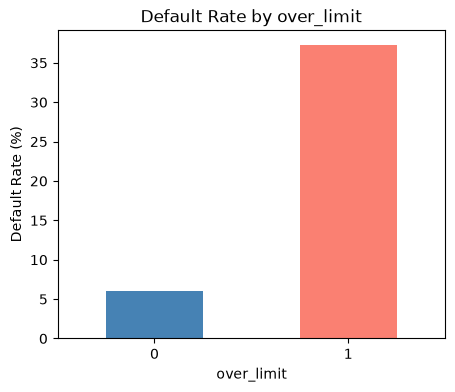

In [29]:
# Visualizing the default rate by over_limit
limit_rate = df.groupby('over_limit')[TARGET].mean() * 100

plt.figure(figsize=(5, 4))
limit_rate.plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Default Rate by over_limit')
plt.xlabel('over_limit')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()

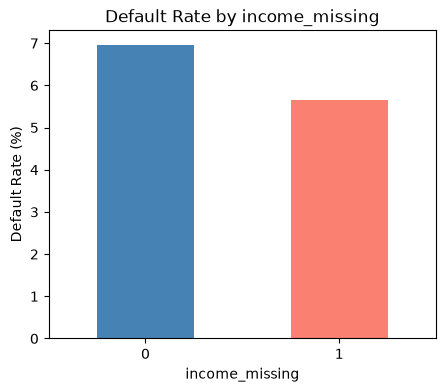

In [30]:
# Visualizing the default rate by income_missing
income_rate = df.groupby('income_missing')[TARGET].mean() * 100

plt.figure(figsize=(5, 4))
income_rate.plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Default Rate by income_missing')
plt.xlabel('income_missing')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()

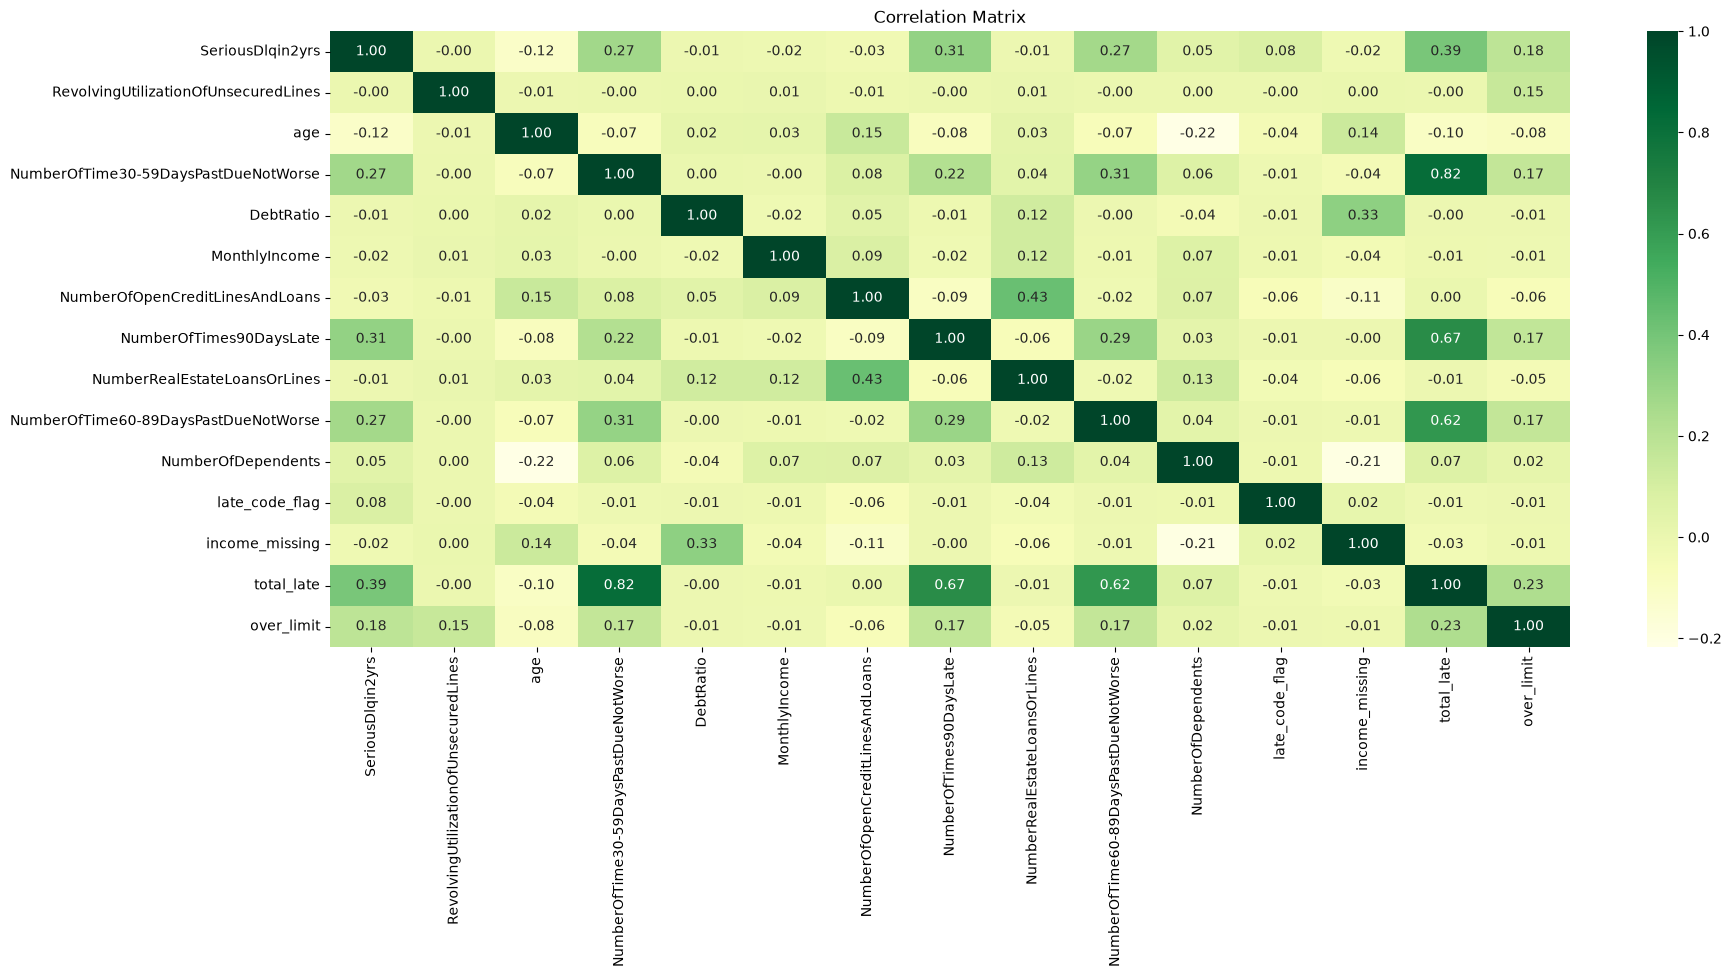

In [31]:
# Drop the group columns made only for the graphs
df = df.drop(columns=['age_group', 'late_group'])

corr = df.corr()
plt.figure(figsize=(20, 8))
sns.heatmap(corr, annot=True, cmap='YlGn', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [32]:
corr[TARGET].sort_values(ascending=False).round(2)

SeriousDlqin2yrs                        1.00
total_late                              0.39
NumberOfTimes90DaysLate                 0.31
NumberOfTime30-59DaysPastDueNotWorse    0.27
NumberOfTime60-89DaysPastDueNotWorse    0.27
over_limit                              0.18
late_code_flag                          0.08
NumberOfDependents                      0.05
RevolvingUtilizationOfUnsecuredLines   -0.00
NumberRealEstateLoansOrLines           -0.01
DebtRatio                              -0.01
MonthlyIncome                          -0.02
income_missing                         -0.02
NumberOfOpenCreditLinesAndLoans        -0.03
age                                    -0.12
Name: SeriousDlqin2yrs, dtype: float64

### EDA Summary
- Only 6.7% of borrowers default, so accuracy will not be used to judge the models.
- Past late payments are the strongest sign of default (2.8% for people never late, 57.2% for people late 5 or more times).
- Younger borrowers and people over their credit limit are riskier.
- The new columns `total_late`, `over_limit` and `late_code_flag` clearly separate risky people, so they are good features. `income_missing` is only a weak signal.

# `Models Part`

## Train Test Split

In [33]:
X = df.drop(TARGET, axis=1)
y = df[TARGET]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Default rate:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape, " Default rate:", round(y_test.mean() * 100, 2), "%")

Train: (119512, 14)  Default rate: 6.7 %
Test : (29878, 14)  Default rate: 6.7 %


Spliting the data **once** and use the same train and test sets for all three models, so the comparison is fair. Because of `stratify=y`, both sets have the same default rate.

### Scaling (only for Logistic Regression)

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Logistic Regression

In [35]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [36]:
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
print(y_pred_lr)

[1 0 1 ... 0 0 0]


In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", accuracy_lr)

# Calculate precision
precision_lr = precision_score(y_test, y_pred_lr)
print("Precision:", precision_lr)

# Calculate recall (sensitivity)
recall_lr = recall_score(y_test, y_pred_lr)
print("Recall:", recall_lr)

# Calculate F1-score
f1_lr = f1_score(y_test, y_pred_lr)
print("F1-score:", f1_lr)

# Calculate ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
print("ROC-AUC:", roc_auc_lr)

Accuracy: 0.859997322444608
Precision: 0.2694015648128568
Recall: 0.6363636363636364
F1-score: 0.3785470212449859
ROC-AUC: 0.82659889256962


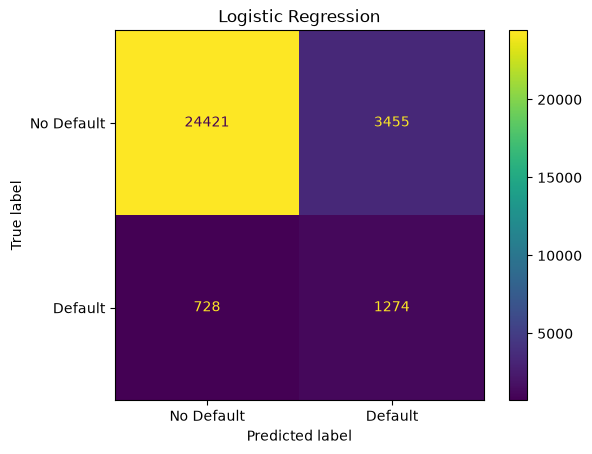

In [38]:
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test, y_pred_lr)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=['No Default', 'Default'])
cm_display.plot()
plt.title('Logistic Regression')
plt.show()

- Logistic Regression catches **64%** of defaulters (recall 0.636) and has a ROC-AUC of **0.827**.
- Precision is low (**0.27**): out of everyone it flags as risky, only about 1 in 4 actually defaults. This is the trade-off of using `class_weight='balanced'`: the model catches more defaulters, but also flags many good customers.
- Accuracy is 86%, lower than the 93% of a model that predicts "no default" for everyone, but this model is actually useful because it finds defaulters.

## Decision Tree

In [39]:
from sklearn.tree import DecisionTreeClassifier

dtree = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dtree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_f

In [40]:
y_pred_dt = dtree.predict(X_test)
y_prob_dt = dtree.predict_proba(X_test)[:, 1]
print(y_pred_dt)

[1 0 1 ... 0 0 0]


In [41]:
# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", accuracy_dt)

# Calculate precision
precision_dt = precision_score(y_test, y_pred_dt)
print("Precision:", precision_dt)

# Calculate recall (sensitivity)
recall_dt = recall_score(y_test, y_pred_dt)
print("Recall:", recall_dt)

# Calculate F1-score
f1_dt = f1_score(y_test, y_pred_dt)
print("F1-score:", f1_dt)

# Calculate ROC-AUC
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
print("ROC-AUC:", roc_auc_dt)

Accuracy: 0.9006292255171029
Precision: 0.2621741269060502
Recall: 0.2662337662337662
F1-score: 0.26418835192069395
ROC-AUC: 0.6061829994514024


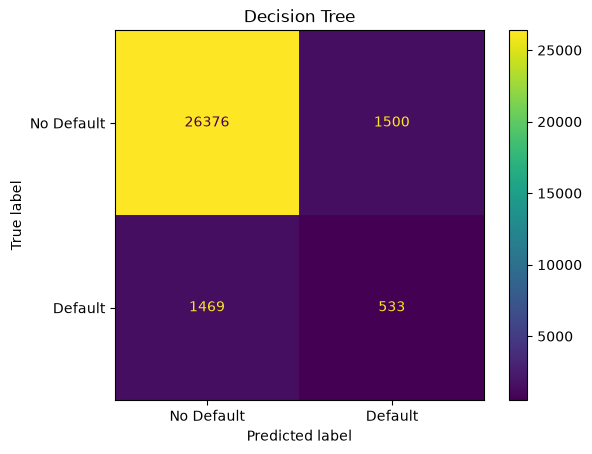

In [42]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred_dt)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=['No Default', 'Default'])
cm_display.plot()
plt.title('Decision Tree')
plt.show()

In [43]:
# how deep did the tree grow?
print("Tree depth:", dtree.get_depth())
print("Number of leaves:", dtree.get_n_leaves())
print("Train accuracy:", accuracy_score(y_train, dtree.predict(X_train)))
print("Test accuracy :", accuracy_dt)

Tree depth: 50
Number of leaves: 11757
Train accuracy: 0.9997155097396078
Test accuracy : 0.9006292255171029


- The Decision Tree has a **very low ROC-AUC (0.61)**, barely better than guessing (0.5).
- The reason is clear from the last cell: without any limit, the tree grew **50 levels deep with 11,757 leaves**. It gets **99.97% accuracy on training data** but only 90% on test data. It **memorized** the training data instead of learning general patterns. This is **overfitting**.

## Random Forest

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [45]:
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
print(y_pred_rf)

[1 0 1 ... 0 0 0]


In [46]:
# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", accuracy_rf)

# Calculate precision
precision_rf = precision_score(y_test, y_pred_rf)
print("Precision:", precision_rf)

# Calculate recall (sensitivity)
recall_rf = recall_score(y_test, y_pred_rf)
print("Recall:", recall_rf)

# Calculate F1-score
f1_rf = f1_score(y_test, y_pred_rf)
print("F1-score:", f1_rf)

# Calculate ROC-AUC
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print("ROC-AUC:", roc_auc_rf)

Accuracy: 0.9248945712564429
Precision: 0.4331491712707182
Recall: 0.3916083916083916
F1-score: 0.41133263378803775
ROC-AUC: 0.8442623616159991


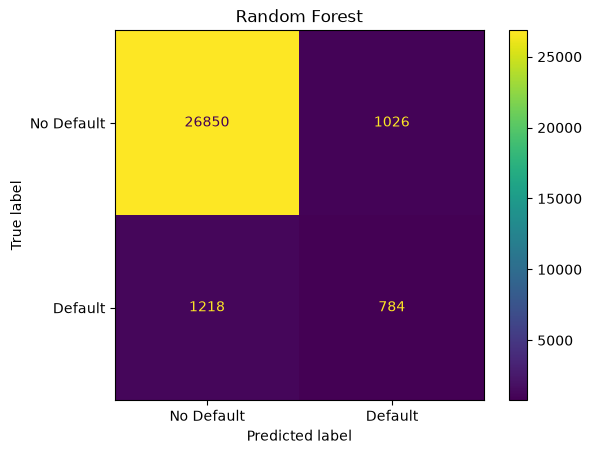

In [47]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred_rf)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=['No Default', 'Default'])
cm_display.plot()
plt.title('Random Forest')
plt.show()

- Random Forest has the **best ROC-AUC so far (0.844)**, the highest accuracy (92.5%), and also the best precision (0.43) and F1 (0.41) of the three models.
- But it catches only **39%** of defaulters (recall 0.392), much lower than Logistic Regression (64%). Its trees are fully grown, so they become very confident that most people are safe, even with `class_weight='balanced'`.
- For a bank this is still weak: it misses about 6 out of every 10 defaulters. Tuning should improve this.

# `Compare Table Result`

In [48]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_lr, accuracy_dt, accuracy_rf],
    'Precision': [precision_lr, precision_dt, precision_rf],
    'Recall': [recall_lr, recall_dt, recall_rf],
    'F1-Score': [f1_lr, f1_dt, f1_rf],
    'ROC-AUC': [roc_auc_lr, roc_auc_dt, roc_auc_rf]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.860,0.269,0.636,0.379,0.827
1,Decision Tree,0.901,0.262,0.266,0.264,0.606
2,Random Forest,0.925,0.433,0.392,0.411,0.844


**Before tuning:**
- Random Forest is the best on ROC-AUC (0.844), precision (0.43), F1 (0.41) and accuracy (92.5%).
- Logistic Regression has the best recall (0.64), but the lowest accuracy and precision, so it flags many good customers.
- Decision Tree is the weakest (ROC-AUC 0.61) because of overfitting.
- No model is good enough yet: even the best recall is only 64%. Tuning should help, especially for the tree models.

# `Grid Part`

In [49]:
from sklearn.model_selection import GridSearchCV

# Define parameter grids for each model
param_grid_lr = {'C': [0.01, 0.1, 1, 10]}

param_grid_dt = {'max_depth': [4, 6, 8, 10],
                 'min_samples_leaf': [50, 100, 200]}

param_grid_rf = {'max_depth': [8, 12],
                 'min_samples_leaf': [20, 50]}

In [50]:
grid_search_lr = GridSearchCV(lr, param_grid_lr, cv=3, scoring='roc_auc')
grid_search_lr.fit(X_train_scaled, y_train)
print("Best parameters for Logistic Regression:", grid_search_lr.best_params_)

grid_search_dt = GridSearchCV(dtree, param_grid_dt, cv=3, scoring='roc_auc')
grid_search_dt.fit(X_train, y_train)
print("Best parameters for Decision Tree:", grid_search_dt.best_params_)

grid_search_rf = GridSearchCV(rf, param_grid_rf, cv=3, scoring='roc_auc')
grid_search_rf.fit(X_train, y_train)
print("Best parameters for Random Forest:", grid_search_rf.best_params_)

Best parameters for Logistic Regression: {'C': 0.01}
Best parameters for Decision Tree: {'max_depth': 6, 'min_samples_leaf': 200}
Best parameters for Random Forest: {'max_depth': 12, 'min_samples_leaf': 50}


In [51]:
# Get the best performing models
best_lr_model = grid_search_lr.best_estimator_
best_dt_model = grid_search_dt.best_estimator_
best_rf_model = grid_search_rf.best_estimator_

# Make predictions on the test set
y_pred_lr_tuned = best_lr_model.predict(X_test_scaled)
y_pred_dt_tuned = best_dt_model.predict(X_test)
y_pred_rf_tuned = best_rf_model.predict(X_test)

y_prob_lr_tuned = best_lr_model.predict_proba(X_test_scaled)[:, 1]
y_prob_dt_tuned = best_dt_model.predict_proba(X_test)[:, 1]
y_prob_rf_tuned = best_rf_model.predict_proba(X_test)[:, 1]

In [52]:
tuned_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr_tuned), accuracy_score(y_test, y_pred_dt_tuned), accuracy_score(y_test, y_pred_rf_tuned)],
    'Precision': [precision_score(y_test, y_pred_lr_tuned), precision_score(y_test, y_pred_dt_tuned), precision_score(y_test, y_pred_rf_tuned)],
    'Recall': [recall_score(y_test, y_pred_lr_tuned), recall_score(y_test, y_pred_dt_tuned), recall_score(y_test, y_pred_rf_tuned)],
    'F1-Score': [f1_score(y_test, y_pred_lr_tuned), f1_score(y_test, y_pred_dt_tuned), f1_score(y_test, y_pred_rf_tuned)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_lr_tuned), roc_auc_score(y_test, y_prob_dt_tuned), roc_auc_score(y_test, y_prob_rf_tuned)]
})

display(tuned_results.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.860,0.270,0.637,0.379,0.827
1,Decision Tree,0.772,0.199,0.797,0.319,0.855
2,Random Forest,0.806,0.224,0.773,0.348,0.864


In [53]:
# Before vs after tuning (ROC-AUC)
compare_auc = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'ROC-AUC Before': [roc_auc_lr, roc_auc_dt, roc_auc_rf],
    'ROC-AUC After': tuned_results['ROC-AUC'].values
})
display(compare_auc.round(3))

,Model,ROC-AUC Before,ROC-AUC After
0,Logistic Regression,0.827,0.827
1,Decision Tree,0.606,0.855
2,Random Forest,0.844,0.864


**After tuning:**
- **Decision Tree** improved the most: ROC-AUC went from **0.606 to 0.855**. Limiting `max_depth` to 6 and `min_samples_leaf` to 200 stopped it from memorizing the data. This proves the overfitting problem.
- **Random Forest** improved from **0.844 to 0.864** ROC-AUC, and its recall jumped from **0.39 to 0.77** after limiting `max_depth=12` and `min_samples_leaf=50`.
- **Logistic Regression** stayed the same (0.827). It is a simple model with fewer settings to tune, so there was little to gain.
- **Trade-off:** after tuning, the tree models catch many more defaulters but also flag more good customers. For the Random Forest, accuracy dropped from 92.5% to 80.6% and precision from 0.43 to 0.22. This is acceptable because missing a defaulter costs the bank more, and the threshold section below shows how to adjust this balance.

**Best model: Tuned Random Forest.** It has the highest ROC-AUC (0.864) and a recall of 0.77. The tuned Decision Tree is close behind (ROC-AUC 0.855), so the Random Forest's advantage is real but small.

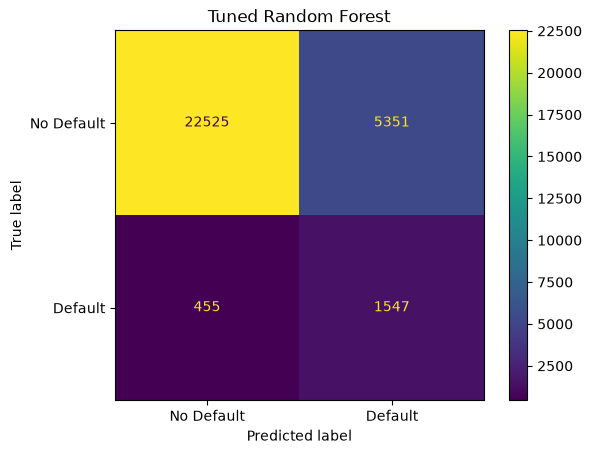

In [54]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred_rf_tuned)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=['No Default', 'Default'])
cm_display.plot()
plt.title('Tuned Random Forest')
plt.show()

Out of **2,002** defaulters in the test set, the tuned Random Forest catches **1,547** and misses **455**.
It also flags **5,351** good customers as risky (out of 27,876). In a real bank, these people would not be rejected automatically but could be sent for a manual check.

# `Changing the Threshold`

In [55]:
for threshold in [0.3, 0.5, 0.7]:
    y_pred_t = (y_prob_rf_tuned >= threshold).astype(int)
    print("Threshold:", threshold,
          "| Precision:", round(precision_score(y_test, y_pred_t), 3),
          "| Recall:", round(recall_score(y_test, y_pred_t), 3),
          "| F1:", round(f1_score(y_test, y_pred_t), 3),
          "| People flagged:", y_pred_t.sum())

Threshold: 0.3 | Precision: 0.142 | Recall: 0.89 | F1: 0.245 | People flagged: 12537
Threshold: 0.5 | Precision: 0.224 | Recall: 0.773 | F1: 0.348 | People flagged: 6898
Threshold: 0.7 | Precision: 0.342 | Recall: 0.587 | F1: 0.432 | People flagged: 3441


- At **0.3**, the model catches **89%** of defaulters but flags 12,537 people, and only 14% of them really default.
- At **0.5** (default), it catches **77%** and flags 6,898 people.
- At **0.7**, it flags only 3,441 people and has the best F1 (**0.43**) and precision (0.34), but catches only **59%** of defaulters.

There is no single "correct" threshold. If missing a defaulter is very costly for the bank, a lower threshold like 0.3 is better. If checking flagged customers is expensive, a higher threshold like 0.7 is better. This is a business decision, not only a technical one.

# `Feature Importance`

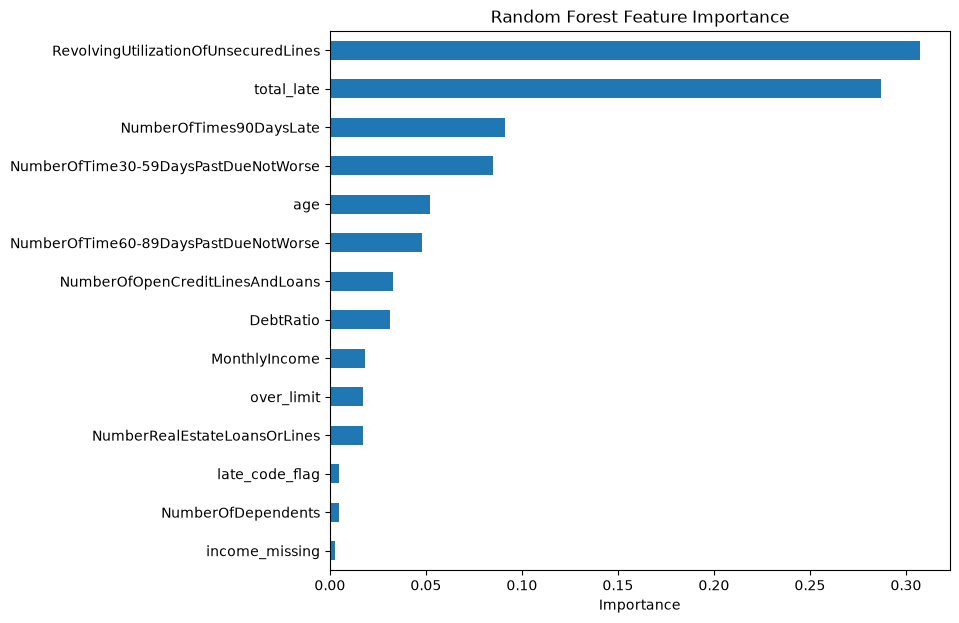

In [56]:
importance = pd.Series(best_rf_model.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind='barh')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()

# Conclusion

**Best model:** Tuned Random Forest (`max_depth=12`, `min_samples_leaf=50`) with **ROC-AUC 0.864** and **recall 0.77**: it catches about 3 out of 4 defaulters (1,547 out of 2,002 in the test set).

**What I learned from this data:**
1. **Accuracy was misleading.** Only 6.7% of people default, so a model that always says "no default" gets 93% accuracy. The untuned Random Forest had 92.5% accuracy but caught only 39% of defaulters.
2. **Past late payments are the strongest predictor.** The default rate goes from 2.8% for people never late to 57% for people late 5 or more times.
3. **"Wrong" values can carry meaning.** The 96/98 codes looked like errors, but those people defaulted 60% of the time. Keeping a flag instead of deleting them kept this information.
4. **Overfitting was the main problem for tree models.** The untuned Decision Tree grew 50 levels deep and scored 99.97% accuracy on training data but only 0.606 ROC-AUC on test data. Limiting its depth raised ROC-AUC to 0.855.
5. **Tuning has a trade-off.** The tuned Random Forest catches many more defaulters (recall 0.39 to 0.77) but also flags more good customers (precision 0.43 to 0.22).
6. **The threshold is a business choice.** Moving it from 0.3 to 0.7 changes recall from 89% to 59%.

**Limitations:**
- Missing values were filled with the median of the whole dataset before splitting. Strictly, the median should come only from the training data. With 150,000 rows the effect is very small, but it is worth noting.
- There is no customer ID, so some removed duplicates might be different people with identical values.
- Precision is low (0.22): more than 3 out of 4 flagged customers do not actually default.
- The tuned Random Forest is only slightly better than the tuned Decision Tree (0.864 vs 0.855), and the tree is easier to explain.